# Tema 6 · Regresión lineal y descenso de gradiente

El primer modelo que aprende: ajustar una recta minimizando el error, paso a paso.

Este cuaderno es el tema 6 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/6-regresion-lineal-y-descenso-de-gradiente/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Una profesora anotó, para cada estudiante de su curso, cuántas horas estudió en la semana del examen y qué nota sacó. Ahora llega una estudiante nueva y le cuenta que estudió seis horas. ¿Qué nota esperarías que saque?

No hay una regla escrita en ningún lado que diga «seis horas dan tal nota». Lo único que tenemos son **ejemplos**: pares de horas y notas. La idea de este tema es que una computadora puede encontrar sola una regla que se ajuste a esos ejemplos y usarla para predecir casos nuevos. A eso se le llama **aprender de los datos**, y el método que vas a programar, el **descenso de gradiente**, es el mismo con el que se entrenan casi todos los modelos de inteligencia artificial, desde una recta hasta una red neuronal enorme.

En este tema vas a:

- definir qué son un **modelo**, sus **parámetros**, una **función de pérdida** y el **entrenamiento**;
- medir el error con el **MSE** y el **MAE**, y saber cuándo conviene cada uno;
- programar desde cero el descenso de gradiente para una regresión lineal;
- leer en la curva de pérdida si la **tasa de aprendizaje** es muy baja, adecuada o demasiado alta;
- usar `LinearRegression` de scikit-learn y comprobar que da lo mismo que tu código.

Necesitas lo del tema 5: la derivada como pendiente, el gradiente que apunta cuesta arriba y la estandarización.

## Actividad: el valle

Antes de cualquier fórmula, juega. A la izquierda hay unos puntos (los ejemplos) y una recta que controlas con dos deslizadores, *w* y *b*. Los cuadrados sombreados son los errores de la recta elevados al cuadrado: el área de cada uno es lo que ese punto «se queja». A la derecha está el **valle**: cada lugar del mapa es una recta posible, y las curvas de nivel unen las rectas que se equivocan lo mismo. La bola coral es tu recta actual.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/6-regresion-lineal-y-descenso-de-gradiente/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Mueve *w* y *b* hasta que los cuadrados sean lo más chicos posible. Mira dónde queda la bola en el mapa.
2. Pulsa «Reiniciar» y luego «Dar un paso» varias veces. La computadora hace lo mismo que tú, pero siguiendo la pendiente del valle. ¿Llega al mismo lugar?
3. Sube el tamaño del paso (la tasa de aprendizaje) hasta que la bola empiece a rebotar de un lado al otro. Súbelo un poco más: ¿qué pasa con el error?
4. Arrastra un punto muy lejos de los demás. ¿Cómo cambian la recta ideal y el valle?
5. Arrastra todos los puntos hacia la derecha. El valle se estira y se vuelve angosto. ¿Te cuesta más llegar al fondo con el mismo tamaño de paso?

Lo que acabas de hacer es todo el tema en pequeño: **entrenar es bajar el valle, y la tasa de aprendizaje es el largo del paso**. El resto es ponerle nombre a cada pieza y escribirla en Python.

## El modelo: una recta con dos perillas

Vamos a trabajar con datos **sintéticos**: los inventamos nosotros con una regla conocida (siete puntos por cada hora de estudio, partiendo de 30) más un poco de ruido al azar, que representa todo lo que las horas no explican (el sueño, los nervios, la suerte). Usar datos inventados tiene una ventaja enorme: como conocemos la regla verdadera, podemos comprobar si nuestro método la encuentra.

Horas: [6.2 3.5 6.9 5.6 0.8]
Notas: [86.2 52.1 75.  64.2 39. ]


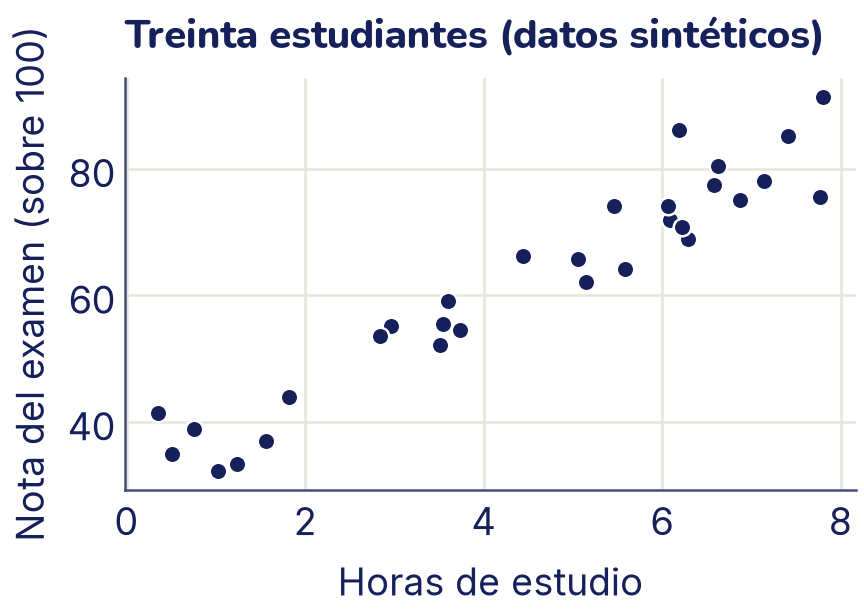

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Semilla fija: cada vez que corras esto saldrán los mismos datos
rng = np.random.default_rng(42)

n = 30                                # cantidad de estudiantes
# Horas de estudio en la semana del examen, entre 0 y 8
horas = rng.uniform(0, 8, size=n)
# Todo lo que las horas no explican (sueño, nervios, suerte)
ruido = rng.normal(0, 6, size=n)
# La regla «secreta»: 7 puntos por hora, partiendo de 30
nota = 30 + 7 * horas + ruido

print("Horas:", np.round(horas[:5], 1))
print("Notas:", np.round(nota[:5], 1))

plt.scatter(horas, nota)
plt.xlabel("Horas de estudio")
plt.ylabel("Nota del examen (sobre 100)")
plt.title("Treinta estudiantes (datos sintéticos)")
plt.show()

Los puntos suben de izquierda a derecha, casi en fila. Una recta parece una buena descripción. En **aprendizaje supervisado** cada ejemplo tiene una **característica** *x* (lo que sabemos: las horas) y un **objetivo** *y* (lo que queremos predecir: la nota). Nuestro **modelo** es una recta:

$$\hat{y} = w \cdot x + b$$

- *ŷ* (se lee «y sombrero») es la **predicción** del modelo. La *y* sin sombrero es la nota real.
- *w* es la **pendiente** o **peso**: cuántos puntos sube la nota por cada hora más.
- *b* es el **intercepto** o término independiente (en inglés, *bias*): la nota que predice la recta para cero horas.

*w* y *b* son los **parámetros** del modelo: las dos perillas que podemos girar. Cada par de valores es una recta distinta. **Entrenar** el modelo es buscar automáticamente los valores de *w* y *b* que mejor se ajustan a los ejemplos. Para eso primero hay que decidir qué significa «mejor».

## Medir el error: residuos y función de pérdida

Probemos una recta elegida a ojo, *w* = 5 y *b* = 40, y miremos cuánto se equivoca con cada estudiante. La diferencia entre la nota real y la predicha se llama **residuo**: si es positivo, la recta se quedó corta; si es negativo, se pasó.

Estudiante 0: estudió 6.2 h, sacó 86.2, la recta dice 71.0, residuo +15.2
Estudiante 1: estudió 3.5 h, sacó 52.1, la recta dice 57.6, residuo -5.4
Estudiante 2: estudió 6.9 h, sacó 75.0, la recta dice 74.3, residuo +0.7


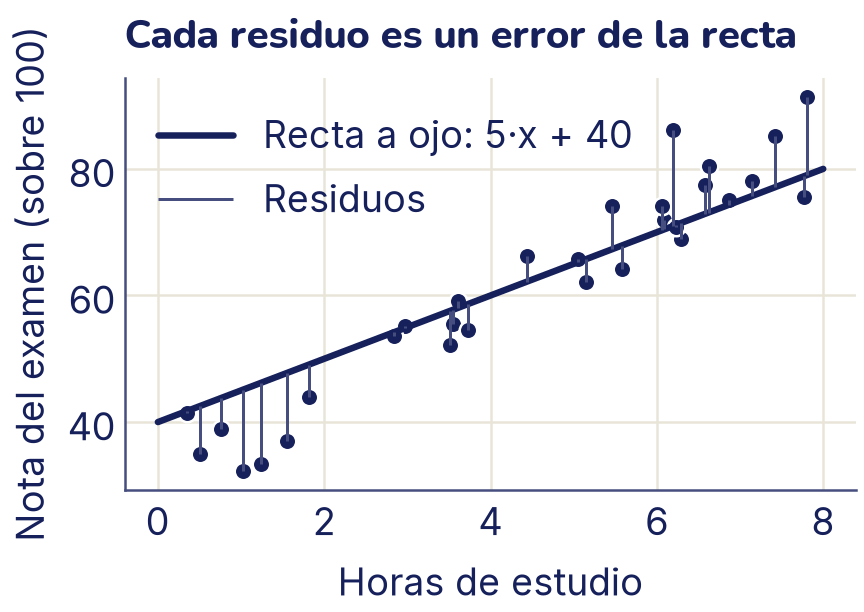

In [ ]:
def predecir(x, w, b):
    """La predicción del modelo: una recta."""
    return w * x + b

# Una primera recta elegida «a ojo»
w, b = 5.0, 40.0
prediccion = predecir(horas, w, b)
residuos = nota - prediccion          # real menos predicho

for i in range(3):
    print(f"Estudiante {i}: estudió {horas[i]:.1f} h, "
          f"sacó {nota[i]:.1f}, la recta dice {prediccion[i]:.1f}, "
          f"residuo {residuos[i]:+.1f}")

# Dos puntos bastan para dibujar una recta
x_recta = np.array([0, 8])
plt.scatter(horas, nota)
plt.plot(x_recta, predecir(x_recta, w, b), color="C0",
         label="Recta a ojo: 5·x + 40")
plt.vlines(horas, prediccion, nota, color="C2", linewidth=1.2,
           label="Residuos")
plt.xlabel("Horas de estudio")
plt.ylabel("Nota del examen (sobre 100)")
plt.title("Cada residuo es un error de la recta")
plt.legend()
plt.show()

Treinta residuos son mucha información. Para comparar rectas necesitamos **un solo número** que resuma qué tan mal le va a una recta: la **función de pérdida**. Las dos más usadas en regresión son estas.

**Error cuadrático medio (MSE).** Se eleva cada residuo al cuadrado (así no importa el signo) y se saca el promedio:

$$\text{MSE} = \frac{1}{n} \sum_{i = 1}^{n} {( {y}_{i} - {\hat{y}}_{i} )}^{2}$$

**Error absoluto medio (MAE).** Se toma el valor absoluto de cada residuo y se saca el promedio:

$$\text{MAE} = \frac{1}{n} \sum_{i = 1}^{n} | {y}_{i} - {\hat{y}}_{i} |$$

El MSE está en unidades al cuadrado («puntos de nota al cuadrado»), que no se pueden imaginar. Por eso se reporta mucho su raíz, el **RMSE** = √MSE, que vuelve a estar en puntos de nota.

In [ ]:
def mse(y, y_pred):
    """Error cuadrático medio."""
    return np.mean((y - y_pred) ** 2)

def mae(y, y_pred):
    """Error absoluto medio."""
    return np.mean(np.abs(y - y_pred))

for w, b in [(5, 40), (7, 30), (9, 20)]:
    p = predecir(horas, w, b)
    error = mse(nota, p)
    print(f"w = {w}, b = {b}:   MSE = {error:4.1f}   "
          f"RMSE = {np.sqrt(error):3.1f}   MAE = {mae(nota, p):3.1f}")

w = 5, b = 40:   MSE = 41.9   RMSE = 6.5   MAE = 5.0
w = 7, b = 30:   MSE = 23.0   RMSE = 4.8   MAE = 4.0
w = 9, b = 20:   MSE = 49.6   RMSE = 7.0   MAE = 5.5


La recta de la regla verdadera (*w* = 7, *b* = 30) tiene el menor error de las tres, como debía ser. No llega a cero porque el ruido no se puede predecir: ninguna recta pasa por los treinta puntos.

### ¿MSE o MAE?

Las dos miden lo mismo de distinta forma, y la diferencia importa:

- El **MSE castiga mucho los errores grandes**. Un residuo de 10 cuenta 100; uno de 20 cuenta 400, el cuádruple. Si un error grande es muy grave en tu problema (por ejemplo, subestimar mucho la carga que soporta un puente), el MSE es una buena elección. Además es suave, sin esquinas, y su derivada es fácil: por eso es la pérdida que vamos a minimizar con el descenso de gradiente.
- El **MAE trata todos los errores por igual** y se deja llevar menos por unos pocos datos raros (atípicos), como una nota mal anotada. Se interpreta directo: «en promedio, me equivoco por tantos puntos».

En los ejercicios vas a ver con números cómo un solo atípico dispara el MSE y apenas mueve el MAE.

## La pérdida es un paisaje

Ahora fijemos *b* = 30 y probemos muchas pendientes *w*. Para cada una calculamos el MSE. Si dibujamos el MSE en función de *w*, aparece algo conocido.

Con b = 30, la mejor pendiente está cerca de w = 7.11


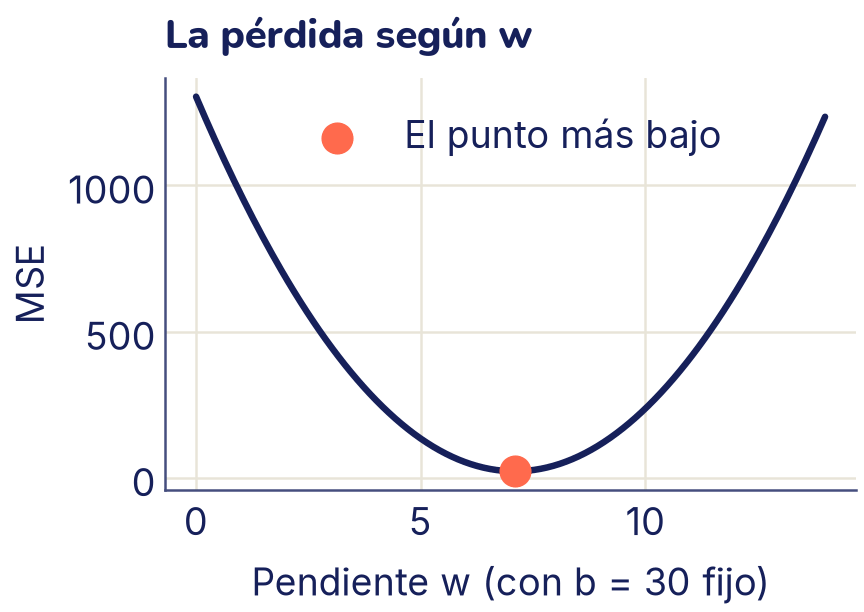

In [ ]:
# 200 pendientes posibles entre 0 y 14
ws = np.linspace(0, 14, 200)
perdidas = [mse(nota, predecir(horas, w, 30)) for w in ws]
mejor = ws[np.argmin(perdidas)]       # la pendiente con menor pérdida

plt.plot(ws, perdidas)
plt.scatter([mejor], [min(perdidas)], color="C1", s=140, zorder=3,
            label="El punto más bajo")
plt.xlabel("Pendiente w (con b = 30 fijo)")
plt.ylabel("MSE")
plt.title("La pérdida según w")
plt.legend()
plt.show()

print(f"Con b = 30, la mejor pendiente está cerca de w = {mejor:.2f}")

Es el valle de la actividad de arriba, cortado a lo largo de una sola dirección: cada valor de *w* es un lugar del valle y su altura es el error. Como el MSE es una suma de cuadrados, el corte es una parábola con un único fondo. (Si viste el [laboratorio de la página de inicio](https://iabolivia.org/#lab-t), es la misma idea, aunque allá el valle es asimétrico a propósito.)

Con los dos parámetros a la vez, la pérdida es una superficie sobre el plano (*w*, *b*): un valle de verdad, con forma de cuenco. Mirado desde arriba se dibuja con **curvas de nivel**, como un mapa topográfico (las viste en el tema 5). Eso es el panel derecho de la actividad.

Encontrar la mejor recta es encontrar **el punto más bajo del valle**. Con dos parámetros podríamos probar una cuadrícula de valores, pero los modelos reales tienen miles o millones de parámetros, y una cuadrícula así no cabe en ninguna computadora. Necesitamos un método que, desde donde estamos, sepa hacia dónde bajar.

## El gradiente: hacia dónde sube el valle

En el tema 5 viste que el **gradiente** de una función de dos variables es el vector de sus derivadas parciales y que apunta hacia donde la función **sube** más rápido. Si queremos bajar, caminamos en contra del gradiente.

Calculemos el gradiente del MSE. Fíjate en un solo estudiante *i*. Su término en la suma es

$${( w {x}_{i} + b - {y}_{i} )}^{2}$$

Por la regla de la cadena, la derivada de «algo al cuadrado» es 2 por ese algo, multiplicado por la derivada de lo de adentro. La derivada de lo de adentro respecto de *w* es *x*<sub>i</sub>, y respecto de *b* es 1. Promediando sobre los *n* estudiantes:

$$\frac{\partial \text{MSE}}{\partial w} = \frac{2}{n} \sum_{i = 1}^{n} ( {\hat{y}}_{i} - {y}_{i} ) \cdot {x}_{i} \qquad \frac{\partial \text{MSE}}{\partial b} = \frac{2}{n} \sum_{i = 1}^{n} ( {\hat{y}}_{i} - {y}_{i} )$$

**Ojo con el signo.** El *residuo* era real − predicho (*y*<sub>i</sub> − *ŷ*<sub>i</sub>). En el gradiente aparece al revés, predicho − real (*ŷ*<sub>i</sub> − *y*<sub>i</sub>), y a eso lo llamamos **error**: es el residuo con el signo cambiado. Un error positivo quiere decir que la recta se pasó.

Las fórmulas se leen con sentido común:

- **Para *b*:** es el doble del error promedio. Si la recta predice notas muy altas en promedio (errores positivos), la derivada es positiva y bajar significa **reducir *b***: mover la recta hacia abajo.
- **Para *w*:** cada error se multiplica por su *x*. Los estudiantes con muchas horas pesan más al decidir la inclinación, porque ahí un cambio de pendiente mueve más la recta.

Antes de confiar en una fórmula hecha a mano, conviene comprobarla. La derivada numérica del tema 5 (con la diferencia centrada) tiene que dar casi lo mismo:

In [ ]:
def gradiente(x, y, w, b):
    """Derivadas parciales del MSE respecto de w y de b."""
    # Error = predicho menos real: el residuo con el signo cambiado
    error = predecir(x, w, b) - y
    dw = 2 * np.mean(error * x)
    db = 2 * np.mean(error)
    return dw, db

def perdida_en(w, b):
    """El MSE de la recta (w, b) con los datos de las notas."""
    return mse(nota, predecir(horas, w, b))

# Comprobación con la derivada numérica (diferencia centrada),
# en la recta a ojo
h = 1e-6
w, b = 5.0, 40.0
dw_num = (perdida_en(w + h, b) - perdida_en(w - h, b)) / (2 * h)
db_num = (perdida_en(w, b + h) - perdida_en(w, b - h)) / (2 * h)
print("Con la fórmula:   ", np.round(gradiente(horas, nota, w, b), 4))
print("Derivada numérica:", np.round([dw_num, db_num], 4))

Con la fórmula:    [-17.1492   0.7425]
Derivada numérica: [-17.1492   0.7425]


Coinciden. Ahora leamos los signos. La derivada respecto de *w* es negativa y grande: si aumentamos *w*, el error baja, así que conviene **inclinar más** la recta. Tiene sentido: la recta a ojo se quedaba corta con los que más estudiaron. La derivada respecto de *b* es positiva y chica: en promedio la recta predice un poquito de más, así que conviene **bajarla** un poco. El gradiente no solo dice hacia dónde ir; también dice cuánto importa cada perilla en este momento.

## Descenso de gradiente: bajar paso a paso

Ya tenemos todo. El **descenso de gradiente** repite una y otra vez:

1. Calcular el gradiente en el lugar donde estamos.
2. Dar un paso pequeño en contra del gradiente.

$$w \leftarrow w - \alpha \cdot \frac{\partial \text{MSE}}{\partial w} \qquad b \leftarrow b - \alpha \cdot \frac{\partial \text{MSE}}{\partial b}$$

La flecha ← significa «se reemplaza por». El número *α* (alfa) es la **tasa de aprendizaje**: el largo del paso. Ojo con un detalle: las dos derivadas se calculan **antes** de mover nada, con los mismos *w* y *b*. Así es en la función de abajo.

In [ ]:
def descenso_gradiente(x, y, tasa, pasos, w=0.0, b=0.0):
    """Ajusta y ≈ w·x + b bajando por el MSE.

    Devuelve los w y b finales y el historial de (w, b, MSE).
    """
    historial = []                    # (w, b, MSE) antes de cada paso
    for paso in range(pasos):
        historial.append((w, b, mse(y, predecir(x, w, b))))
        dw, db = gradiente(x, y, w, b)  # hacia dónde sube el valle
        w = w - tasa * dw             # un paso en contra
        b = b - tasa * db
    historial.append((w, b, mse(y, predecir(x, w, b))))
    return w, b, np.array(historial)

w_final, b_final, historial = descenso_gradiente(
    horas, nota, tasa=0.02, pasos=2000)

for paso in [0, 1, 10, 100, 500, 2000]:
    w_p, b_p, perdida = historial[paso]
    print(f"Paso {paso:4d}:   w = {w_p:5.2f}   b = {b_p:5.2f}"
          f"   MSE = {perdida:7.1f}")

Paso    0:   w =  0.00   b =  0.00   MSE =  4122.9
Paso    1:   w = 12.59   b =  2.48   MSE =   208.6
Paso   10:   w = 11.63   b =  4.45   MSE =   174.7
Paso  100:   w =  9.14   b = 18.51   MSE =    56.7
Paso  500:   w =  6.97   b = 30.72   MSE =    22.5
Paso 2000:   w =  6.89   b = 31.18   MSE =    22.5


Partimos de la recta *w* = 0, *b* = 0 (predice cero para todos). En el primer paso el error baja de más de 4000 a unos 200; después baja más despacio, y hacia el paso 500 ya casi no cambia. Terminamos muy cerca de la regla verdadera, 7 y 30. No llegamos exactamente a 7 y 30 porque con solo treinta estudiantes el ruido inclina un poco la recta: el descenso encuentra la mejor recta **para estos datos**, que es lo único que puede ver.

Veamos la recta en algunos momentos del entrenamiento:

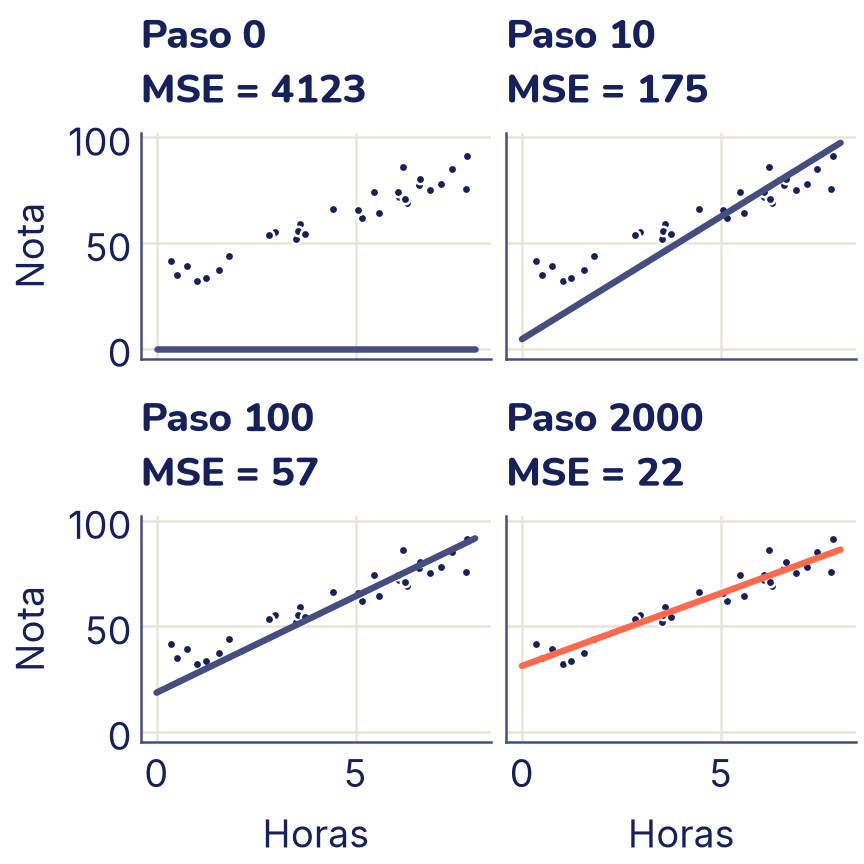

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, paso in zip(ejes.flat, [0, 10, 100, 2000]):
    w_p, b_p, perdida = historial[paso]
    # Solo la recta final va resaltada (color "C1")
    color = "C1" if paso == 2000 else "C2"
    eje.scatter(horas, nota, s=14)
    eje.plot(x_recta, predecir(x_recta, w_p, b_p), color=color)
    # Título en dos líneas para que quepa en cada panel
    eje.set_title(f"Paso {paso}\nMSE = {perdida:.0f}")
for eje in ejes[1]:
    eje.set_xlabel("Horas")
for eje in ejes[:, 0]:
    eje.set_ylabel("Nota")
plt.show()

Y el camino completo sobre el mapa del valle. Para dibujar el mapa calculamos el MSE en una cuadrícula de 200 × 200 rectas; el *broadcasting* del tema 3 hace las 40 000 cuentas de una vez.

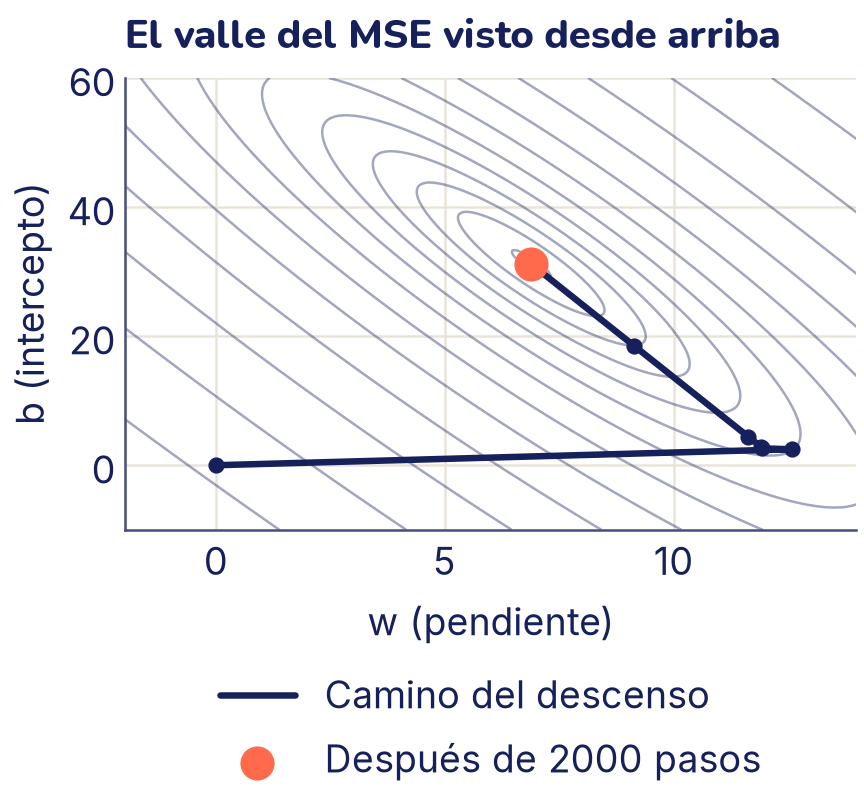

In [ ]:
# Una cuadrícula de 200 × 200 valores de (w, b)
W, B = np.meshgrid(np.linspace(-2, 14, 200), np.linspace(-10, 60, 200))
# Solo para dibujar: el MSE de las 40 000 rectas a la vez. [..., None]
# agrega un eje al final para combinarlo con los 30 estudiantes; no
# necesitas entender cada detalle
Z = np.mean((W[..., None] * horas + B[..., None] - nota) ** 2, axis=-1)

niveles = np.geomspace(Z.min() + 1, Z.max(), 14)
# Más alta que la de siempre: la leyenda va debajo
plt.figure(figsize=(4.8, 4.4))
plt.contour(W, B, Z, levels=niveles, colors="C2", linewidths=1,
            alpha=0.5)
plt.plot(historial[:, 0], historial[:, 1], color="C0",
         label="Camino del descenso")
algunos = [0, 1, 2, 3, 10, 100]       # algunos pasos, marcados
plt.scatter(historial[algunos, 0], historial[algunos, 1],
            color="C0", s=30, zorder=3)
plt.scatter([w_final], [b_final], color="C1", s=160, zorder=4,
            label="Después de 2000 pasos")
plt.xlabel("w (pendiente)")
plt.ylabel("b (intercepto)")
plt.title("El valle del MSE visto desde arriba")
# La leyenda va debajo del gráfico, para no tapar las curvas
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24),
           frameon=False)
plt.show()

Mira la forma del camino. El primer paso es enorme: cruza el valle angosto de una ladera a la otra y el error baja de 4123 a 209 de un golpe. En ese salto *w* se pasa de largo (llega a 12,6). Después la bola avanza despacio por un fondo largo y casi plano, bajando *w* y subiendo *b* a la vez, hasta llegar a la bola coral. Eso pasa porque el valle es **alargado**: subir *w* un poquito cambia mucho la pérdida (las horas llegan hasta 8 y multiplican a *w*), mientras que mover *b* y *w* juntos en la dirección del fondo apenas la cambia. Es lo mismo que viste al arrastrar todos los puntos a la derecha en la actividad. Cuando las características se **estandarizan** (media 0 y desviación 1, como en el tema 5), el valle se vuelve mucho más redondo y el descenso llega en menos pasos. Lo vas a usar en la sección de varias variables.

## La tasa de aprendizaje

La tasa de aprendizaje es la decisión más importante del descenso de gradiente. Comparemos tres tasas con los mismos datos y el mismo punto de partida:

tasa 0.002:  MSE después de 600 pasos = 89.11
tasa 0.02:  MSE después de 600 pasos = 22.48
tasa 0.04:  MSE después de 600 pasos = 1.228e+52


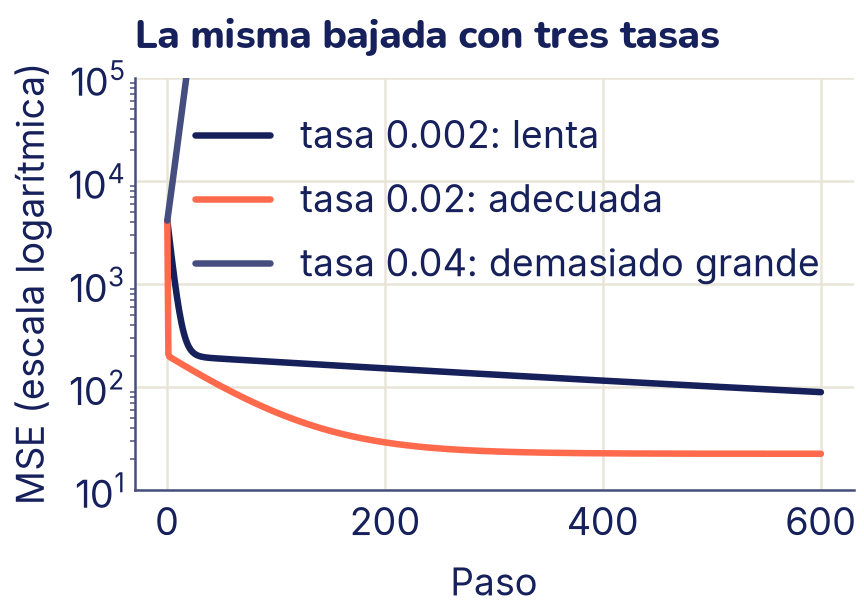

In [ ]:
tasas = [(0.002, "C0", "lenta"),
         (0.02, "C1", "adecuada"),
         (0.04, "C2", "demasiado grande")]

plt.figure()
for tasa, color, nombre in tasas:
    _, _, h = descenso_gradiente(horas, nota, tasa=tasa, pasos=600)
    plt.plot(h[:, 2], color=color, label=f"tasa {tasa}: {nombre}")
    print(f"tasa {tasa}:  MSE después de 600 pasos = {h[-1, 2]:.4g}")

# Escala logarítmica: cada marca del eje es 10 veces la anterior
plt.yscale("log")
plt.ylim(10, 1e5)
plt.xlabel("Paso")
plt.ylabel("MSE (escala logarítmica)")
plt.title("La misma bajada con tres tasas")
plt.legend()
plt.show()

La **curva de pérdida** (el error frente al número de paso) es el primer gráfico que se mira al entrenar cualquier modelo. Aprende a leerla:

| Lo que ves en la curva | Diagnóstico | Qué hacer |
|---|---|---|
| Baja, pero muy despacio y sin aplanarse | Tasa **demasiado baja** | Subir la tasa (por ejemplo, ×3 o ×10) o dar más pasos |
| Baja rápido y luego se aplana | Tasa **adecuada**: el modelo **convergió** | Nada; ya se puede parar |
| Sube, oscila cada vez más o aparece `nan` o `inf` | Tasa **demasiado alta**: el modelo **diverge** | Bajar la tasa (por ejemplo, ÷3 o ÷10) |

¿Por qué una tasa grande hace subir el error, si cada paso va cuesta abajo? Porque el gradiente solo dice hacia dónde bajar **justo donde estás**. Si el paso es demasiado largo, cruzas el fondo y caes en la otra ladera, más arriba que antes. El paso siguiente es todavía más largo (el gradiente allá es más grande) y la bola se escapa del valle. Es el rebote que viste en la actividad.

Se dice que el descenso **converge** cuando la pérdida deja de bajar de forma apreciable. En la práctica se para cuando el cambio de la pérdida entre pasos es muy chico, o tras un número fijo de pasos que se eligió mirando la curva.

## La solución de scikit-learn

Para la regresión lineal hay un atajo: la mejor recta se puede calcular de un solo golpe resolviendo un sistema de ecuaciones, la llamada **ecuación normal**. No hace falta que la sepas deducir; basta saber que existe y que scikit-learn la usa (con un método numérico estable) en `LinearRegression`.

Todos los modelos de scikit-learn tienen la misma interfaz: se crean, se **entrenan** con `fit(X, y)` y **predicen** con `predict(X)`. `X` siempre es una tabla, con una fila por ejemplo y una columna por característica; por eso convertimos las horas en una columna con `reshape(-1, 1)`.

In [ ]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
# X tiene que ser una tabla: 30 filas y 1 columna
modelo.fit(horas.reshape(-1, 1), nota)

print(f"scikit-learn:      w = {modelo.coef_[0]:.4f}"
      f"   b = {modelo.intercept_:.4f}")
print(f"Nuestro descenso:  w = {w_final:.4f}   b = {b_final:.4f}")
print("Nota predicha para 6 horas:", modelo.predict([[6]]).round(1))

scikit-learn:      w = 6.8895   b = 31.1769
Nuestro descenso:  w = 6.8895   b = 31.1769
Nota predicha para 6 horas: [72.5]


Nuestro descenso de gradiente llegó al mismo resultado que scikit-learn. Y ya tenemos respuesta para la pregunta del principio: con seis horas de estudio, el modelo predice unos 72,5 puntos. Es una **predicción**, no una promesa: los puntos de la nube están a varios puntos de la recta.

¿Para qué aprender el descenso de gradiente si existe la ecuación normal? Porque la ecuación normal solo sirve para modelos lineales con el MSE, y se vuelve lenta con muchísimas características. El descenso de gradiente sirve para casi cualquier modelo y cualquier pérdida derivable. Es exactamente el mismo bucle que vas a usar para entrenar redes neuronales en la fase 4.

## Varias variables a la vez

Casi nunca una sola característica alcanza para predecir bien. Con *d* características, el modelo tiene un peso para cada una:

$$\hat{y} = {w}_{1} {x}_{1} + {w}_{2} {x}_{2} + \cdots + {w}_{d} {x}_{d} + b$$

Si ponemos los ejemplos como filas de una matriz *X* (de *n* filas y *d* columnas) y los pesos en un vector *w*, las *n* predicciones salen todas juntas con un producto matriz por vector (tema 3), y el gradiente también:

$$\hat{\mathbf{y}} = X \mathbf{w} + b \qquad {\nabla}_{\mathbf{w}} \text{MSE} = \frac{2}{n} {X}^{T} ( \hat{\mathbf{y}} - \mathbf{y} )$$

Es la misma fórmula de antes, «error por *x*, promediado», hecha para todos los pesos a la vez. *X*<sup>T</sup> es la **transpuesta** de *X* (tema 3): sus filas son las columnas de *X*. Por eso *X*<sup>T</sup> por el vector de errores hace, para cada columna *j*, la suma Σ<sub>*i*</sub> *x*<sub>*ij*</sub> · error<sub>*i*</sub>: cada error por el valor de esa columna, sumado sobre los ejemplos. Por ejemplo, con 3 filas y 2 columnas, *X* = [[1, 2], [3, 0], [2, 1]] y errores (1, −1, 2), la columna 1 da 1 · 1 + 3 · (−1) + 2 · 2 = 2 y la columna 2 da 2 · 1 + 0 · (−1) + 1 · 2 = 4, así que *X*<sup>T</sup> · error = (2, 4).

Vamos a usar un conjunto de datos real que viene incluido en scikit-learn (no hay que descargar nada): **diabetes**. Tiene 442 pacientes, 10 características medidas al inicio y, como objetivo, una medida numérica de cuánto avanzó la enfermedad un año después.

| Columna | Qué es |
|---|---|
| `age`, `sex` | Edad y sexo |
| `bmi` | Índice de masa corporal |
| `bp` | Presión arterial promedio |
| `s1` a `s6` | Seis medidas de un análisis de sangre (colesterol total, LDL, HDL, colesterol total / HDL, triglicéridos, azúcar) |

In [ ]:
from sklearn.datasets import load_diabetes
import pandas as pd

diabetes = load_diabetes(as_frame=True)
X = diabetes.data      # tabla: 442 pacientes × 10 características
y = diabetes.target    # avance de la enfermedad un año después

print("Forma de X:", X.shape)
print("Columnas:", list(X.columns))
print("Objetivo: de", y.min(), "a", y.max(),
      "con media", round(y.mean(), 1))

Forma de X: (442, 10)
Columnas: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Objetivo: de 25.0 a 346.0 con media 152.1


Las columnas vienen con escalas muy chicas (scikit-learn ya las centró y achicó). Para que el valle sea redondo y una sola tasa de aprendizaje sirva para todos los pesos, las **estandarizamos** como en el tema 5: a cada columna le restamos su media y la dividimos por su desviación estándar. Después programamos el descenso de gradiente con matrices; son las mismas líneas de antes, ahora con `@`, el producto de matrices:

In [ ]:
# Estandarizar: cada columna queda con media 0 y desviación estándar 1
X_est = ((X - X.mean()) / X.std(ddof=0)).to_numpy()
y_arr = y.to_numpy()

def descenso_gradiente_varias(X, y, tasa, pasos):
    """Descenso de gradiente para y ≈ X @ w + b (un peso por columna)."""
    n, d = X.shape
    w = np.zeros(d)                   # un peso por característica
    b = 0.0
    for paso in range(pasos):
        error = X @ w + b - y         # los n errores de una vez
        w = w - tasa * 2 * X.T @ error / n
        b = b - tasa * 2 * np.mean(error)
    return w, b

w_gd, b_gd = descenso_gradiente_varias(X_est, y_arr, tasa=0.1,
                                       pasos=20000)
modelo_diabetes = LinearRegression().fit(X_est, y_arr)

comparacion = pd.DataFrame(
    {"descenso": w_gd, "scikit-learn": modelo_diabetes.coef_},
    index=X.columns)
print(comparacion.round(2))
print(f"b:  descenso = {b_gd:.2f}"
      f"   scikit-learn = {modelo_diabetes.intercept_:.2f}")

     descenso  scikit-learn
age     -0.48         -0.48
sex    -11.41        -11.41
bmi     24.73         24.73
bp      15.43         15.43
s1     -37.68        -37.68
s2      22.68         22.68
s3       4.81          4.81
s4       8.42          8.42
s5      35.73         35.73
s6       3.22          3.22
b:  descenso = 152.13   scikit-learn = 152.13


Otra vez el mismo resultado. Como las columnas están estandarizadas, los pesos se pueden comparar entre sí: subir una desviación estándar el índice de masa corporal (`bmi`) aumenta la predicción en unos 25 puntos, si las demás características quedan iguales. Cuidado con leer demasiado en cada peso por separado: `s1` y `s2` miden cosas muy relacionadas (colesterol total y LDL) y sus pesos grandes y de signo contrario en buena parte se compensan. Que un peso sea grande no prueba que esa variable **cause** la enfermedad; el modelo solo encontró una relación en los datos.

## ¿Qué tan bueno es el modelo?

El MSE y el MAE dicen cuánto se equivoca el modelo, pero en las unidades del problema: ¿un RMSE de 53 es mucho o poco? Depende de cuánto varían los datos. El **coeficiente de determinación R²** compara el modelo con el más tonto posible, el que siempre predice el promedio *ȳ*:

$${R}^{2} = 1 - \frac{\sum_{i = 1}^{n} {( {y}_{i} - {\hat{y}}_{i} )}^{2}}{\sum_{i = 1}^{n} {( {y}_{i} - \overline{y} )}^{2}}$$

- **R² = 1**: predicciones perfectas.
- **R² = 0**: el modelo no es mejor que predecir siempre el promedio.
- **R² negativo**: es peor que el promedio (pasa, por ejemplo, con una tasa de aprendizaje que divergió).

Además de los números, hay que **mirar los residuos**. Un buen gráfico es el de residuos frente a predicciones: si el modelo captó todo lo que una recta puede captar, los puntos forman una nube sin forma alrededor de cero. Si ves una curva o un embudo, hay algo que el modelo lineal no está viendo.

RMSE = 53.5   MAE = 43.3   R² = 0.518
R² según scikit-learn: 0.518
R² usando solo bmi: 0.344


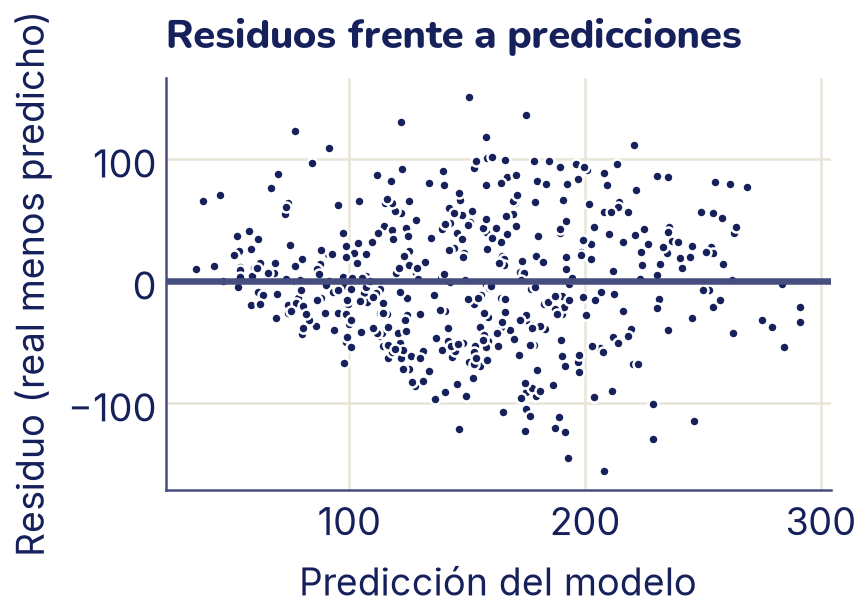

In [ ]:
from sklearn.metrics import r2_score

pred = modelo_diabetes.predict(X_est)
residuos = y_arr - pred
r2 = 1 - np.sum(residuos ** 2) / np.sum((y_arr - y_arr.mean()) ** 2)
rmse = np.sqrt(np.mean(residuos ** 2))
error_abs = np.mean(np.abs(residuos))

print(f"RMSE = {rmse:.1f}   MAE = {error_abs:.1f}   R² = {r2:.3f}")
print(f"R² según scikit-learn: {r2_score(y_arr, pred):.3f}")

# Un modelo con una sola columna: bmi (la de índice 2)
solo_bmi = X_est[:, [2]]
modelo_bmi = LinearRegression().fit(solo_bmi, y_arr)
print(f"R² usando solo bmi: {modelo_bmi.score(solo_bmi, y_arr):.3f}")

plt.scatter(pred, residuos, s=16)
plt.axhline(0, color="C2")
plt.xlabel("Predicción del modelo")
plt.ylabel("Residuo (real menos predicho)")
plt.title("Residuos frente a predicciones")
plt.show()

Con las diez características el modelo explica cerca de la mitad de la variación del avance de la enfermedad; con solo `bmi`, bastante menos. Los residuos no muestran una forma evidente, pero son grandes: una recta en diez dimensiones no alcanza para predecir con precisión algo tan complejo.

Hay una trampa escondida en estos números: los medimos **con los mismos pacientes que usamos para entrenar**. Es como corregir un examen con las preguntas que el estudiante ya vio resueltas. En el tema 7 vas a ver cómo medir a un modelo con datos que nunca vio, que es lo que de verdad importa.

## Lo que aprendiste y lo que sigue

- Un **modelo** es una fórmula con **parámetros** (aquí *w* y *b*); **entrenar** es elegir los parámetros que minimizan una **función de pérdida** sobre los ejemplos.
- El **MSE** castiga los errores grandes y es fácil de derivar; el **MAE** es más robusto a los atípicos y se lee directo en las unidades del problema.
- La pérdida es un **paisaje** sobre el espacio de parámetros. El **descenso de gradiente** lo baja repitiendo «calcular el gradiente, dar un paso en contra».
- La **tasa de aprendizaje** es el largo del paso: muy chica, tarda; muy grande, diverge. La curva de pérdida te dice cuál es el caso.
- `LinearRegression` de scikit-learn da el mismo resultado con `fit` y `predict`, la interfaz que vas a ver en todos los modelos.

Este mismo bucle (predecir, medir el error, calcular el gradiente, dar un paso) vuelve en la regresión logística (tema 8), en las redes neuronales (temas 16 a 19) y en el ajuste fino de modelos grandes. Lo que cambia es el modelo y la pérdida, no la idea.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `horas`, `nota`, `predecir`, `mse`, `mae`, `gradiente`, `descenso_gradiente`, `modelo` (la recta de las horas y las notas), `X_est`, `y_arr`, `descenso_gradiente_varias` y `modelo_diabetes`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta: equivocarse primero y corregir después es como se aprende de verdad.

## Ejercicios

### 1. Las piezas del aprendizaje

En el ejemplo de las horas de estudio y las notas, di qué es cada cosa:

1. La recta ŷ = w·x + b.
2. Los números *w* y *b*.
3. El MSE.
4. Repetir pasos de descenso de gradiente hasta que el error deje de bajar.
5. Las horas de estudio, y la nota.

<details>
<summary>Respuesta</summary>

1. El **modelo**: la forma de la regla que usamos para predecir.
2. Los **parámetros**: los números del modelo que se ajustan con los datos.
3. La **función de pérdida**: un solo número que dice qué tan mal predice el modelo con esos parámetros.
4. El **entrenamiento**: buscar los parámetros que hacen mínima la pérdida.
5. Las horas son la **característica** (la entrada, *x*) y la nota es el **objetivo** (lo que queremos predecir, *y*). Como cada ejemplo trae su respuesta, es **aprendizaje supervisado**.

</details>

### 2. MSE y MAE a mano

Cuatro puntos: (1, 3), (2, 5), (3, 4) y (4, 8). Para la recta ŷ = x + 2, calcula sin computadora los residuos, el MSE, el RMSE y el MAE. Después compruébalo con las funciones `mse` y `mae` de la teoría.

<details>
<summary>Respuesta</summary>

Las predicciones son 3, 4, 5 y 6. Los residuos (real menos predicho) son 0, 1, −1 y 2.

- MSE = (0 + 1 + 1 + 4) / 4 = **1,5**
- RMSE = √1,5 ≈ **1,22**
- MAE = (0 + 1 + 1 + 2) / 4 = **1**

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x = np.array([1, 2, 3, 4])
y = np.array([3, 5, 4, 8])
p = x + 2
print("Residuos:", y - p)
print(f"MSE = {mse(y, p)}   RMSE = {np.sqrt(mse(y, p)):.2f}"
      f"   MAE = {mae(y, p)}")

### 3. El gradiente a mano

a) Partiendo de MSE = (1/n) · Σ (w·xᵢ + b − yᵢ)², deriva tú mismo la derivada parcial respecto de *b*. Escribe cada paso y di qué regla usas.

b) Con los cuatro puntos del ejercicio 2 y la recta *w* = 1, *b* = 2, calcula las dos derivadas parciales.

c) Da un paso de descenso de gradiente con tasa α = 0,1. ¿Cuáles son los nuevos *w* y *b*? ¿Bajó el MSE?

<details>
<summary>Respuesta</summary>

a) La derivada de una suma es la suma de las derivadas, y la constante 1/n sale afuera. Para cada término usamos la regla de la cadena: la derivada de u² es 2u por la derivada de u. Aquí u = w·xᵢ + b − yᵢ, y su derivada respecto de *b* es 1 (*w*, *xᵢ* e *yᵢ* no dependen de *b*). Entonces

∂MSE/∂b = (1/n) · Σ 2 · (w·xᵢ + b − yᵢ) · 1 = (2/n) · Σ (ŷᵢ − yᵢ),

es decir, el doble del error promedio (predicho menos real).

b) Los errores ŷ − y son 0, −1, 1 y −2.

- ∂MSE/∂b = 2 · (0 − 1 + 1 − 2) / 4 = **−1**
- ∂MSE/∂w = 2 · (0·1 − 1·2 + 1·3 − 2·4) / 4 = 2 · (−7/4) = **−3,5**

c) *w* = 1 − 0,1 · (−3,5) = **1,35** y *b* = 2 − 0,1 · (−1) = **2,1**. El MSE baja de 1,5 a **1,279**. Las dos derivadas eran negativas, así que el paso aumentó *w* y *b*: la recta se inclinó más y subió, porque se quedaba corta con el último punto.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
dw, db = gradiente(x, y, 1, 2)
print("dw =", dw, "  db =", db)
w, b = 1 - 0.1 * dw, 2 - 0.1 * db
print(f"Después del paso: w = {w:.2f}   b = {b:.2f}")
print(f"MSE antes = {mse(y, predecir(x, 1, 2)):.3f}"
      f"   después = {mse(y, predecir(x, w, b)):.3f}")

### 4. ¿Qué tasa es cuál?

Se entrenó la recta de la teoría (las 30 notas, partiendo de *w* = 0, *b* = 0) tres veces, cada una con una tasa de aprendizaje distinta, A, B y C. La tabla de abajo muestra el MSE en algunos pasos. Para cada entrenamiento, di si la tasa es **lenta**, **adecuada** o **demasiado grande**, y qué harías.

In [ ]:
# @title El código que hizo la tabla (muestra las tasas: ábrelo al final): código (doble clic para verlo)
pasos_tabla = [0, 1, 2, 5, 10, 50, 100, 300]
curvas = {}
for nombre, tasa in [("A", 0.03), ("B", 0.039), ("C", 0.005)]:
    _, _, h = descenso_gradiente(horas, nota, tasa=tasa, pasos=300)
    curvas[nombre] = h[pasos_tabla, 2]

tabla = pd.DataFrame({"Paso": pasos_tabla, **curvas})
print(tabla.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

```text
 Paso     A         B     C
    0  4123      4123  4123
    1  1486      4479  2336
    2 616.5      4868  1363
    5 196.1      6269 385.9
   10 162.6      9623 203.9
   50  74.1 3.225e+05 168.6
  100  37.3 2.652e+07 141.3
  300 22.57 1.213e+15 74.43
```

<details>
<summary>Respuesta</summary>

- **A, adecuada**: baja rápido y en el paso 300 ya está en 22,57, casi el mínimo (22,47, el de la teoría). Se puede parar.
- **B, demasiado grande**: el error sube desde el primer paso y cada vez más rápido. El descenso diverge: hay que bajar la tasa. Fíjate en que al principio sube despacio: con una tasa apenas por encima del límite, la divergencia tarda en notarse.
- **C, lenta**: baja todo el tiempo, pero en 300 pasos todavía está en 74,43. Funciona, pero conviene subir la tasa o dar muchos más pasos.

Las tasas eran A = 0,03, B = 0,039 y C = 0,005.

</details>

### 5. Un atípico: MSE frente a MAE

El estudiante de índice 5 es el que más estudió. Imagina que al pasar las notas alguien se equivocó y le anotó un 0.

In [ ]:
nota_mala = nota.copy()
nota_mala[5] = 0                      # el error al pasar las notas
print(f"Horas: {horas[5]:.1f}   nota real: {nota[5]:.1f}")

Horas: 7.8   nota real: 91.4


a) Sin volver a entrenar, calcula el MSE y el MAE de la recta de scikit-learn de la teoría (`modelo`, entrenado con las notas correctas) antes y después del error. ¿Cuántas veces crece cada uno?

b) Vuelve a entrenar `LinearRegression` con `nota_mala`. ¿Cuánto cambian *w* y *b*?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
pred = modelo.predict(horas.reshape(-1, 1))
antes = mse(nota, pred), mae(nota, pred)
despues = mse(nota_mala, pred), mae(nota_mala, pred)
print(f"MSE: {antes[0]:.1f} -> {despues[0]:.1f}"
      f"   ({despues[0] / antes[0]:.1f} veces)")
print(f"MAE: {antes[1]:.2f} -> {despues[1]:.2f}"
      f"   ({despues[1] / antes[1]:.1f} veces)")
print(f"Residuo del dato malo: {nota_mala[5] - pred[5]:.1f}")

modelo_malo = LinearRegression().fit(horas.reshape(-1, 1), nota_mala)
print(f"Antes:   w = {modelo.coef_[0]:.2f}   b = {modelo.intercept_:.2f}")
print(f"Después: w = {modelo_malo.coef_[0]:.2f}"
      f"   b = {modelo_malo.intercept_:.2f}")

<details>
<summary>Respuesta</summary>

a) Con la misma recta, el MSE crece casi 12 veces y el MAE apenas 1,7 veces. Un solo residuo de unos 85 puntos, elevado al cuadrado, pesa más que los otros 29 juntos.

b) Un solo dato malo entre treinta le baja la pendiente en casi dos puntos por hora y le sube el intercepto en más de cinco. Como `LinearRegression` minimiza el MSE, hereda su sensibilidad a los atípicos. Por eso siempre conviene **mirar los datos** antes de entrenar (tema 4) y, si hay atípicos que no se pueden corregir, considerar el MAE.

</details>

### 6. ¿Hasta dónde se puede subir la tasa?

Con los datos de la teoría, prueba tasas entre 0,036 y 0,039 con 2000 pasos y busca la más grande con la que el descenso todavía converge. Escribe un bucle; no lo hagas a mano.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for tasa in [0.036, 0.037, 0.038, 0.0385, 0.039]:
    _, _, h = descenso_gradiente(horas, nota, tasa=tasa, pasos=2000)
    print(f"tasa {tasa}:  MSE final = {h[-1, 2]:.4g}")

<details>
<summary>Respuesta</summary>

Con 0,038 todavía converge al mínimo (22,47) y con 0,0385 ya diverge: el límite está **entre 0,038 y 0,0385**. Ese límite depende de los datos: cuanto más grandes son los valores de *x*, más empinadas son las paredes del valle y más chico tiene que ser el paso. Es otra razón para estandarizar.

</details>

### 7. Pocos pasos con muchas variables

En la teoría entrenamos el modelo de diabetes con 20 000 pasos. Repite el entrenamiento con solo 300 pasos y compara con scikit-learn (`modelo_diabetes`): el MSE y los pesos de `bmi`, `s1` y `s2`. ¿Qué observas? ¿Cómo lo explicas?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
w_300, b_300 = descenso_gradiente_varias(X_est, y_arr, tasa=0.1, pasos=300)
error_300 = np.mean((X_est @ w_300 + b_300 - y_arr) ** 2)
error_min = np.mean((modelo_diabetes.predict(X_est) - y_arr) ** 2)
print(f"MSE con 300 pasos: {error_300:.1f}   mínimo: {error_min:.1f}"
      f"   ({100 * (error_300 / error_min - 1):.1f} % más)")

pesos = pd.DataFrame({"300 pasos": w_300,
                      "scikit-learn": modelo_diabetes.coef_},
                     index=X.columns)
print(pesos.loc[["bmi", "s1", "s2"]].round(2))

<details>
<summary>Respuesta</summary>

El MSE ya está a menos de medio punto porcentual del mínimo y el peso de `bmi` está casi bien, pero los pesos de `s1` y `s2` siguen lejos de los de scikit-learn.

La explicación es que `s1` (colesterol total) y `s2` (LDL) están muy correlacionadas: subir una y bajar la otra casi no cambia las predicciones. En el valle eso es un fondo largo y casi plano, y el descenso avanza por ahí muy despacio. Moraleja: que la pérdida ya casi no baje no garantiza que cada peso haya llegado a su valor final, y los pesos de variables muy relacionadas entre sí hay que interpretarlos con cuidado.

</details>

### 8. Predecir fuera de los datos

Con el `modelo` de las horas y las notas, predice la nota de alguien que estudió 0 horas y la de alguien que estudió 12 horas. ¿Tienen sentido las dos respuestas?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("Predicciones para 0 y 12 horas:",
      modelo.predict([[0], [12]]).round(1))
print(f"Horas en los datos: de {horas.min():.2f} a {horas.max():.2f}")

<details>
<summary>Respuesta</summary>

La de 12 horas no tiene sentido: el examen es sobre 100. El modelo solo vio estudiantes de 0,35 a 7,80 horas; fuera de ese rango no sabe nada, y una recta sigue subiendo para siempre. Predecir fuera del rango de los datos se llama **extrapolar**. Las 0 horas también están fuera del rango, pero apenas: 0,35 horas por debajo del que menos estudió. Es una extrapolación pequeña y la predicción es razonable. Las 12 horas, en cambio, están más de 4 horas por encima del que más estudió, y ahí la recta ya inventa.

</details>

### 9. Leer el R²

Tres modelos de regresión, medidos con los mismos datos con que se entrenaron, dan R² = 0,95, R² = 0 y R² = −0,3. ¿Qué significa cada uno?

<details>
<summary>Respuesta</summary>

- **0,95**: el modelo explica el 95 % de la variación del objetivo; sus errores son chicos comparados con cuánto varían los datos.
- **0**: predecir siempre el promedio daría el mismo error. El modelo no aporta nada.
- **−0,3**: es peor que predecir el promedio. Con una regresión lineal bien entrenada y medida en sus propios datos de entrenamiento eso no puede pasar, así que algo falló: por ejemplo, un descenso que divergió o que paró demasiado pronto.

Un R² alto en los datos de entrenamiento todavía no dice cómo le irá al modelo con datos nuevos. Eso lo ves en el tema 7.

</details>

## Mini-proyecto: el precio de las viviendas

Vas a predecir el valor de las viviendas de una zona con una sola variable y después con todas, y a comparar.

**Los datos.** El conjunto *California Housing* viene en scikit-learn y se descarga de internet la primera vez que lo pides (pesa menos de 1 MB); después queda guardado. Tiene 20 640 zonas de California según el censo de 1990 de Estados Unidos. El objetivo, `MedHouseVal`, es el valor mediano de las viviendas de la zona en cientos de miles de dólares (2,5 significa 250 000 dólares).

| Columna | Qué es |
|---|---|
| `MedInc` | Ingreso mediano de los hogares de la zona (en decenas de miles de dólares) |
| `HouseAge` | Antigüedad mediana de las casas, en años |
| `AveRooms`, `AveBedrms` | Promedio de habitaciones y de dormitorios por vivienda |
| `Population`, `AveOccup` | Habitantes de la zona y personas por vivienda |
| `Latitude`, `Longitude` | Ubicación de la zona |

In [ ]:
from sklearn.datasets import fetch_california_housing

# La primera vez necesita internet; después queda guardado
casas = fetch_california_housing(as_frame=True)
X = casas.data
y = casas.target.to_numpy()
print(X.shape)

(20640, 8)


**Pasos.**

1. **Mira los datos.** Grafica `MedHouseVal` frente a `MedInc` (con `plt.scatter(..., s=2, alpha=0.3)`, porque son muchos puntos). ¿Ves una tendencia? ¿Qué pasa arriba, en el valor 5? Cuenta cuántas zonas tienen exactamente ese valor máximo.
2. **Una variable, desde cero.** Estandariza `MedInc` y entrena con tu función `descenso_gradiente` de la teoría. Elige la tasa y el número de pasos mirando la curva de pérdida. Guarda la curva como figura.
3. **Una variable, con scikit-learn.** Entrena `LinearRegression` con `MedInc` sin estandarizar. Para comparar con tu resultado, vuelve tus *w* y *b* a las unidades originales: si estandarizaste con media *m* y desviación *s*, la pendiente original es *w*/*s* y el intercepto es *b* − *w*·*m*/*s*. ¿Coinciden?
4. **Todas las variables.** Estandariza las 8 columnas y entrena `LinearRegression`. Si te animas, entrena también `descenso_gradiente_varias` y compara los pesos.
5. **Compara.** Haz una tabla con RMSE, MAE y R² para el modelo de una variable y el de ocho. Dibuja los residuos frente a las predicciones del modelo de ocho variables.
6. **Concluye.** Escribe tres conclusiones de una o dos frases cada una. Por ejemplo: ¿cuánto mejora usar todas las variables? ¿Qué variable tiene el peso más grande (en valor absoluto) en el modelo estandarizado y qué podría significar? ¿Qué forma rara ves en el gráfico de residuos y de dónde sale?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 5 sin gráficos; tus números deberían coincidir.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.metrics import r2_score

ingreso = X["MedInc"].to_numpy()
print("Zonas con el valor máximo:", (y == y.max()).sum(),
      "  valor máximo:", y.max())

# Paso 2: una variable, desde cero, con MedInc estandarizado
m, s = ingreso.mean(), ingreso.std()
w_e, b_e, _ = descenso_gradiente((ingreso - m) / s, y, tasa=0.1, pasos=500)
print(f"Descenso, estandarizado:  w = {w_e:.3f}   b = {b_e:.3f}")
print(f"Descenso, original:       w = {w_e / s:.3f}"
      f"   b = {b_e - w_e * m / s:.3f}")

# Paso 3: una variable, con scikit-learn
una = LinearRegression().fit(ingreso.reshape(-1, 1), y)
print(f"scikit-learn:             w = {una.coef_[0]:.3f}"
      f"   b = {una.intercept_:.3f}")

# Paso 4: las ocho variables, estandarizadas
X8 = ((X - X.mean()) / X.std(ddof=0)).to_numpy()
todas = LinearRegression().fit(X8, y)
print(pd.Series(todas.coef_, index=X.columns).round(2).to_string())

# Paso 5: comparar
for nombre, p in [("1 variable ", una.predict(ingreso.reshape(-1, 1))),
                  ("8 variables", todas.predict(X8))]:
    print(f"{nombre}:  RMSE = {np.sqrt(mse(y, p)):.3f}"
          f"   MAE = {mae(y, p):.3f}   R² = {r2_score(y, p):.3f}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

- Muchas zonas tienen exactamente el valor máximo: los valores del censo se recortaron arriba («500 000 dólares o más»). Eso deja una línea recta de residuos en el gráfico, porque el modelo predice valores por encima de 5 que nunca aparecen en los datos.
- Con solo `MedInc`, cada 10 000 dólares de ingreso mediano suman unos 41 800 dólares al valor de la vivienda. El descenso con `MedInc` estandarizado llega a lo mismo que scikit-learn, una vez que se vuelve a las unidades originales.
- Con las 8 variables, el R² sube de 0,47 a 0,61. Los pesos más grandes del modelo estandarizado son los de `Latitude`, `Longitude` y `MedInc`: la ubicación importa casi tanto como el ingreso.
- Todo esto está medido con los mismos datos del entrenamiento. En el tema 7 vas a repetir el mini-proyecto midiendo con datos que el modelo no vio.

</details>

## Errores comunes

- **Una tasa de aprendizaje demasiado grande.** Si la pérdida sube, oscila o aparece `nan` o `inf`, baja la tasa (dividiéndola por 3 o por 10) antes de buscar otro error.
- **Actualizar *w* y después usar el *w* nuevo para calcular el paso de *b*.** Las dos derivadas se calculan primero, con los mismos *w* y *b*, y recién después se actualizan los dos.
- **Olvidar el promedio en el gradiente.** Si sumas en lugar de promediar, el gradiente crece con la cantidad de datos y una tasa que funcionaba con 30 ejemplos diverge con 3000.
- **Confundir el signo.** El gradiente apunta cuesta arriba: el paso es `w - tasa * dw`, no `w + tasa * dw`. Si el error sube con cualquier tasa, revisa el signo.
- **No estandarizar con varias variables.** Si una característica va de 0 a 1 y otra de 0 a 10 000, el valle es tan alargado que ninguna tasa sirve para las dos.
- **Dar a scikit-learn una lista en lugar de una tabla.** `fit` espera `X` con forma (ejemplos, características). Con una sola variable usa `x.reshape(-1, 1)`; si no, verás un error que habla de «2D array».
- **Comparar MSE de problemas distintos.** El MSE está en unidades al cuadrado y depende de la escala del objetivo. Para interpretarlo, usa el RMSE (mismas unidades que *y*) o el R².
- **Creer que un R² alto en el entrenamiento garantiza buenas predicciones.** Un modelo puede ir muy bien con los datos que ya vio y mal con datos nuevos (tema 7).
- **Extrapolar.** Una recta no sabe nada fuera del rango de los datos con que se entrenó.
- **Leer un peso como causa.** Un peso grande dice que la variable ayuda a predecir en estos datos, no que la cause.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Definir modelo, parámetros, función de pérdida y entrenamiento (ejercicio 1).
- Calcular el MSE y el MAE, y explicar cuándo conviene cada uno (ejercicios 2 y 5).
- Programar desde cero el descenso de gradiente para una regresión lineal (ejercicio 3 y pasos 2 y 4 del mini-proyecto).
- Diagnosticar con la curva de pérdida una tasa de aprendizaje baja, adecuada o demasiado alta (ejercicios 4 y 6).
- Usar `LinearRegression` de scikit-learn y comparar sus coeficientes con los tuyos (pasos 3 y 4 del mini-proyecto).